In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.diagnostic import acorr_ljungbox

from statsmodels.tsa.stattools import acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

from statsmodels.tsa.arima_process import ArmaProcess
from statsmodels.tsa.arima.model import ARIMA

In [9]:
# !python -m pip install --trusted-host pypi.org --trusted-host files.pythonhosted.org pandas numpy matplotlib statsmodels

In [10]:
url = (
    "https://raw.githubusercontent.com/tirthajyoti/Deep-learning-with-Python/"
    "80f337d1584fb123f1a8f7dce0ad190f1a08ce14/"
    "Data/historical-hourly-weather-data/humidity.csv"
)

In [11]:
humidity = pd.read_csv(url)

In [12]:
humidity

,datetime,Vancouver,Portland,San Francisco,Seattle,Los Angeles,San Diego,Las Vegas,Phoenix,Albuquerque,...,Philadelphia,New York,Montreal,Boston,Beersheba,Tel Aviv District,Eilat,Haifa,Nahariyya,Jerusalem
0,2012-10-01 12:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,25.0,NaN,NaN,NaN
1,2012-10-01 13:00:00,76.0,81.0,88.0,81.0,88.0,82.0,22.0,23.0,50.0,...,71.0,58.0,93.0,68.0,50.0,63.0,22.0,51.0,51.0,50.0
2,2012-10-01 14:00:00,76.0,80.0,87.0,80.0,88.0,81.0,21.0,23.0,49.0,...,70.0,57.0,91.0,68.0,51.0,62.0,22.0,51.0,51.0,50.0
3,2012-10-01 15:00:00,76.0,80.0,86.0,80.0,88.0,81.0,21.0,23.0,49.0,...,70.0,57.0,87.0,68.0,51.0,62.0,22.0,51.0,51.0,50.0
4,2012-10-01 16:00:00,77.0,80.0,85.0,79.0,88.0,81.0,21.0,23.0,49.0,...,69.0,57.0,84.0,68.0,52.0,62.0,22.0,51.0,51.0,50.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45248,2017-11-29 20:00:00,NaN,81.0,NaN,93.0,24.0,72.0,18.0,68.0,37.0,...,27.0,NaN,64.0,37.0,NaN,NaN,NaN,NaN,NaN,NaN
45249,2017-11-29 21:00:00,NaN,71.0,NaN,87.0,21.0,72.0,18.0,73.0,34.0,...,29.0,NaN,59.0,74.0,NaN,NaN,NaN,NaN,NaN,NaN
45250,2017-11-29 22:00:00,NaN,71.0,NaN,93.0,23.0,68.0,17.0,60.0,32.0,...,31.0,NaN,66.0,74.0,NaN,NaN,NaN,NaN,NaN,NaN
45251,2017-11-29 23:00:00,NaN,71.0,NaN,87.0,14.0,63.0,17.0,33.0,30.0,...,26.0,NaN,58.0,56.0,NaN,NaN,NaN,NaN,NaN,NaN


In [13]:
humidity.shape

(45253, 37)

In [14]:
humidity.dtypes[:3]

datetime         str
Vancouver    float64
Portland     float64
dtype: object

In [15]:
humidity = pd.read_csv(url, index_col='datetime', parse_dates=['datetime'])

In [16]:
humidity.dtypes[:3]

Vancouver        float64
Portland         float64
San Francisco    float64
dtype: object

In [17]:
humidity_seattle = humidity["Seattle"]

<Axes: xlabel='datetime'>

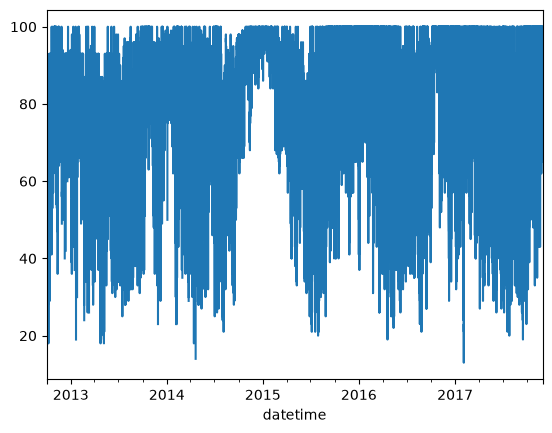

In [18]:
humidity_seattle.plot()

In [19]:
humidity_seattle = humidity_seattle.ffill()

In [20]:
humidity_seattle = humidity_seattle.iloc[1:]

In [21]:
humidity_seattle.isnull().sum()

np.int64(0)

datetime
2012-10-01 13:00:00     81.0
2012-10-02 13:00:00     67.0
2012-10-03 13:00:00     81.0
2012-10-04 13:00:00     63.0
2012-10-05 13:00:00     66.0
                       ...  
2017-11-25 13:00:00     81.0
2017-11-26 13:00:00     87.0
2017-11-27 13:00:00     87.0
2017-11-28 13:00:00     81.0
2017-11-29 13:00:00    100.0
Freq: D, Name: Seattle, Length: 1886, dtype: float64


<Axes: xlabel='datetime'>

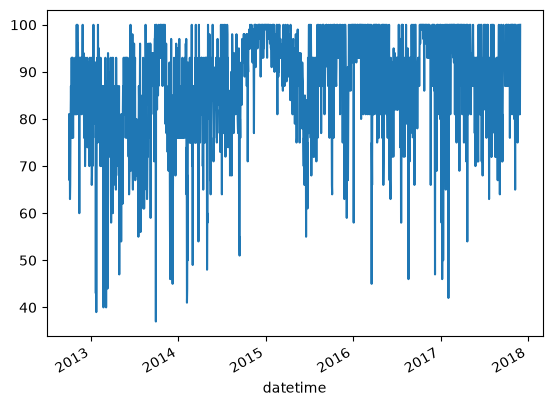

In [22]:
humidity_seattle_asfreq = humidity_seattle.asfreq("D", method="bfill") 
print(humidity_seattle_asfreq)
humidity_seattle_asfreq.plot()

datetime
2012-10-01    78.000000
2012-10-02    65.166667
2012-10-03    58.416667
2012-10-04    48.125000
2012-10-05    48.250000
                ...    
2017-11-26    93.291667
2017-11-27    85.416667
2017-11-28    85.750000
2017-11-29    92.041667
2017-11-30    75.000000
Freq: D, Name: Seattle, Length: 1887, dtype: float64


<Axes: xlabel='datetime'>

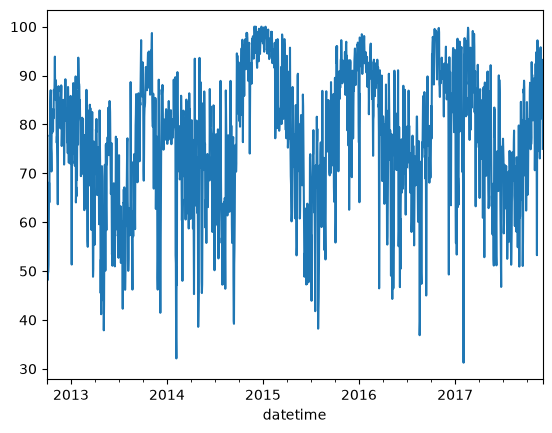

In [23]:
humidity_seattle_resample = humidity_seattle.resample('D').mean()
print(humidity_seattle_resample)
humidity_seattle_resample.plot()

In [24]:
humidity_seattle_2016 = humidity_seattle.loc["2016-01-01":"2016-12-12"]
humidity_seattle_2016

datetime
2016-01-01 00:00:00    70.0
2016-01-01 01:00:00    86.0
2016-01-01 02:00:00    92.0
2016-01-01 03:00:00    92.0
2016-01-01 04:00:00    72.0
                       ... 
2016-12-12 19:00:00    81.0
2016-12-12 20:00:00    87.0
2016-12-12 21:00:00    81.0
2016-12-12 22:00:00    81.0
2016-12-12 23:00:00    86.0
Name: Seattle, Length: 8328, dtype: float64

<Axes: xlabel='datetime'>

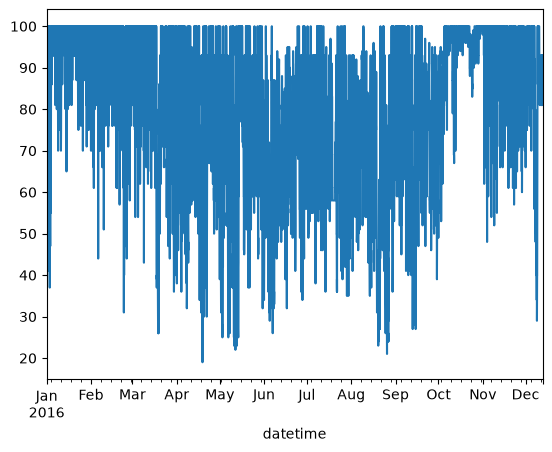

In [25]:
humidity_seattle_2016.plot()

In [26]:
humidity_seattle_2016_resample = humidity_seattle_2016.resample("D").mean()

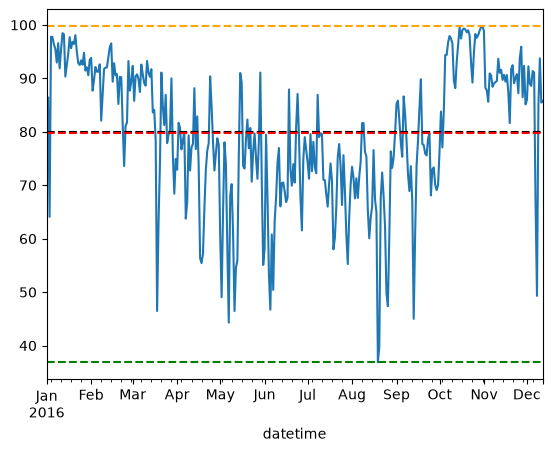

In [27]:
ax = humidity_seattle_2016_resample.plot()
ax.axhline(humidity_seattle_2016_resample.min(), color='green', linestyle='--')
ax.axhline(humidity_seattle_2016_resample.max(), color='orange', linestyle='--')
ax.axhline(humidity_seattle_2016_resample.mean(), color='black', linestyle='--')
ax.axhline(humidity_seattle_2016_resample.median(), color='red', linestyle='--')

<Axes: xlabel='datetime'>

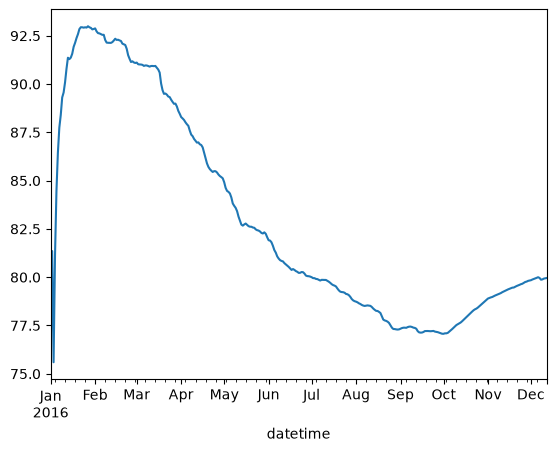

In [28]:
# Expanding window average
humidity_seattle_2016_resample_expanding = humidity_seattle_2016_resample.expanding().mean()
humidity_seattle_2016_resample_expanding.plot()

<Axes: xlabel='datetime'>

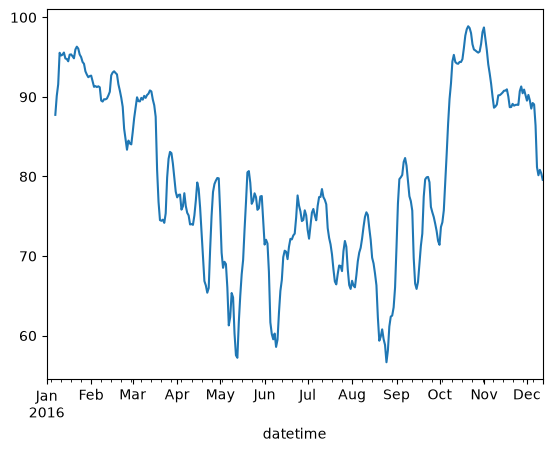

In [29]:
humidity_seattle_2016_resample_smooth = humidity_seattle_2016_resample.rolling(window=7).mean()
humidity_seattle_2016_resample_smooth.plot()

<Axes: xlabel='datetime'>

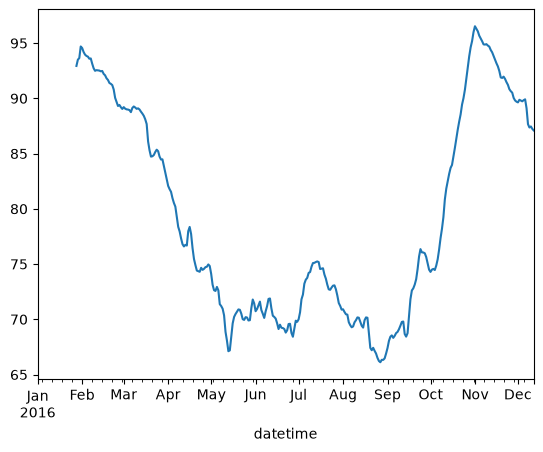

In [30]:
humidity_seattle_2016_resample_smooth = humidity_seattle_2016_resample.rolling(window=28).mean()
humidity_seattle_2016_resample_smooth.plot()

In [31]:
from statsmodels.tsa.stattools import acovf

In [32]:
acovf(humidity_seattle_2016_resample, nlag=1)

array([167.1672503 , 133.85618429])

In [33]:
acovf(humidity_seattle_2016_resample, nlag=7)

array([167.1672503 , 133.85618429, 104.53629005,  94.10395542,
        95.78164163,  96.56072626,  91.15414261,  85.79098178])

In [34]:
acovf(humidity_seattle_2016_resample, nlag=14)

array([167.1672503 , 133.85618429, 104.53629005,  94.10395542,
        95.78164163,  96.56072626,  91.15414261,  85.79098178,
        80.53608152,  79.28714825,  78.46112932,  75.23652097,
        75.283134  ,  73.62552736,  73.9400652 ])

In [35]:
acovf(humidity_seattle_2016_resample, nlag=130)

array([ 1.67167250e+02,  1.33856184e+02,  1.04536290e+02,  9.41039554e+01,
        9.57816416e+01,  9.65607263e+01,  9.11541426e+01,  8.57909818e+01,
        8.05360815e+01,  7.92871483e+01,  7.84611293e+01,  7.52365210e+01,
        7.52831340e+01,  7.36255274e+01,  7.39400652e+01,  7.47521222e+01,
        7.05923162e+01,  6.56590138e+01,  6.48268734e+01,  6.83614459e+01,
        7.29059503e+01,  7.21727647e+01,  6.79322654e+01,  6.88615341e+01,
        6.88139477e+01,  6.78509707e+01,  5.84962871e+01,  5.49642238e+01,
        5.37317195e+01,  6.00395097e+01,  6.25123219e+01,  6.02960120e+01,
        5.67535998e+01,  5.42448900e+01,  4.97782990e+01,  4.66254320e+01,
        4.61575326e+01,  4.30629453e+01,  4.10608788e+01,  4.12129058e+01,
        3.76060632e+01,  3.57164052e+01,  3.13747742e+01,  3.10571071e+01,
        3.46870332e+01,  3.37043668e+01,  2.80038656e+01,  2.05878622e+01,
        1.82457470e+01,  1.74320379e+01,  1.80982857e+01,  1.29029351e+01,
        1.15951260e+01,  

In [36]:
adfuller(humidity_seattle_2016_resample)[1]

C:\Users\n.osipov\AppData\Local\Temp\ipykernel_42760\35571409.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adfuller(humidity_seattle_2016_resample)[1]


0.015438425629570228

In [37]:
kpss(humidity_seattle_2016_resample)[1]

C:\Users\n.osipov\AppData\Local\Temp\ipykernel_42760\1931668556.py:1: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  kpss(humidity_seattle_2016_resample)[1]


np.float64(0.022983913556805423)

In [38]:
humidity_seattle_2016_resample_diff = humidity_seattle_2016_resample.diff()

In [39]:
humidity_seattle_2016_resample_diff = humidity_seattle_2016_resample_diff.dropna()

In [40]:
adfuller(humidity_seattle_2016_resample_diff)[1]

C:\Users\n.osipov\AppData\Local\Temp\ipykernel_42760\1254792049.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adfuller(humidity_seattle_2016_resample_diff)[1]


1.0579861025209811e-25

In [41]:
kpss(humidity_seattle_2016_resample_diff)[1]

C:\Users\n.osipov\AppData\Local\Temp\ipykernel_42760\2757783992.py:1: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss(humidity_seattle_2016_resample_diff)[1]
C:\Users\n.osipov\AppData\Local\Temp\ipykernel_42760\2757783992.py:1: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  kpss(humidity_seattle_2016_resample_diff)[1]


np.float64(0.1)

In [42]:
acorr_ljungbox(humidity_seattle_2016_resample_diff, return_df=True, lags=14)

,lb_stat,lb_pvalue
1,1.188123,2.757086e-01
2,30.574417,2.295354e-07
3,41.276659,5.712722e-09
4,41.455845,2.162698e-08
5,44.221220,2.088650e-08
6,44.238142,6.630284e-08
7,44.239724,1.920415e-07
8,45.478379,2.986154e-07
9,45.496958,7.465211e-07
10,45.956776,1.460331e-06


array([ 1.        , -0.05834619, -0.28975035, -0.17460504,  0.02255989,
        0.08849659, -0.00691252, -0.0021106 , -0.05896658, -0.00721099,
        0.03582076, -0.04711789,  0.02582396, -0.03273319, -0.00566403])

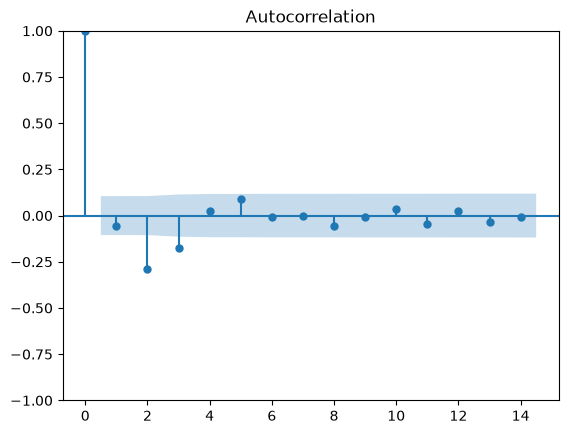

In [43]:
plot_acf(humidity_seattle_2016_resample_diff, lags=14)
acf(humidity_seattle_2016_resample_diff, nlags=14)

**График ACF**

*Как интерпретировать:*

* *Медленный спад*: указывает на сильную устойчивость зависимости. Такое бывает и у нестационарных рядов, и у стационарных AR-процессов с коэффициентом, близким к 1, поэтому одного графика недостаточно для вывода о стационарности.
* *Сезонность*: периодические пики могут указывать на сезонность. Например, для месячных данных пики могут появляться на лагах 12, 24 и т.д.
* *Быстрый спад*: означает, что зависимость между далёкими наблюдениями быстро ослабевает.

*Как читать график:*

* *Доверительные интервалы* (по умолчанию 95%) помогают оценить статистическую значимость: значения внутри интервала считаются незначимыми.
* *Значимые значения ACF* (вне интервала) указывают на наличие корреляции на соответствующих лагах.


array([ 1.        , -0.05851531, -0.29587206, -0.23703494, -0.12609522,
       -0.05951186, -0.08808584, -0.02324517, -0.09018955, -0.05038895,
       -0.02280593, -0.1049928 , -0.01140152, -0.08827051, -0.06087363])

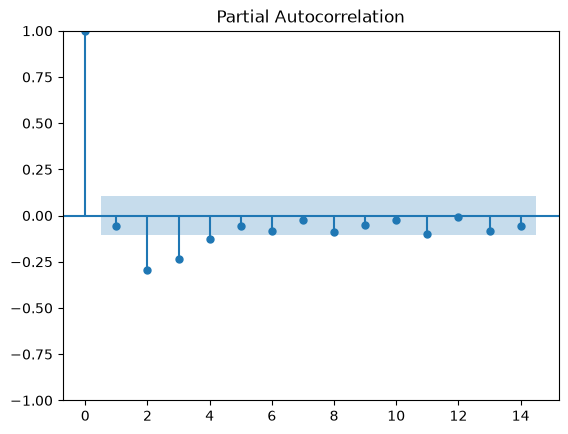

In [44]:
plot_pacf(humidity_seattle_2016_resample_diff, lags=14)
pacf(humidity_seattle_2016_resample_diff, nlags=14)

In [45]:
# Создаём модель
model = ARIMA(humidity_seattle_2016_resample_diff, order=(0,0,1)) # параметры задаются как (p,d,q), где p — AR, q — MA

# Обучаем модель
results = model.fit()

In [46]:
print(results.summary())

                               SARIMAX Results                                
Dep. Variable:                Seattle   No. Observations:                  346
Model:                 ARIMA(0, 0, 1)   Log Likelihood               -1215.857
Date:                Tue, 06 Oct 2026   AIC                           2437.715
Time:                        13:55:21   BIC                           2449.254
Sample:                    01-02-2016   HQIC                          2442.310
                         - 12-12-2016                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0240      0.371      0.065      0.948      -0.703       0.751
ma.L1         -0.1808      0.038     -4.730      0.000      -0.256      -0.106
sigma2        66.0296      3.366     19.619      0.0

In [47]:
model = ARIMA(humidity_seattle_2016_resample_diff, order=(0,0,2)) # параметры задаются как (p,d,q), где p — AR, q — MA

# Обучаем модель
results = model.fit()

In [48]:
print(results.summary())

                               SARIMAX Results                                
Dep. Variable:                Seattle   No. Observations:                  346
Model:                 ARIMA(0, 0, 2)   Log Likelihood               -1188.282
Date:                Tue, 06 Oct 2026   AIC                           2384.564
Time:                        13:55:21   BIC                           2399.949
Sample:                    01-02-2016   HQIC                          2390.690
                         - 12-12-2016                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0026      0.137     -0.019      0.985      -0.271       0.266
ma.L1         -0.2788      0.038     -7.261      0.000      -0.354      -0.204
ma.L2         -0.4263      0.046     -9.340      0.0

In [49]:
model = ARIMA(humidity_seattle_2016_resample_diff, order=(1,0,1)) # параметры задаются как (p,d,q), где p — AR, q — MA

# Обучаем модель
results = model.fit()

In [50]:
print(results.summary())

                               SARIMAX Results                                
Dep. Variable:                Seattle   No. Observations:                  346
Model:                 ARIMA(1, 0, 1)   Log Likelihood               -1190.549
Date:                Tue, 06 Oct 2026   AIC                           2389.097
Time:                        13:55:21   BIC                           2404.483
Sample:                    01-02-2016   HQIC                          2395.224
                         - 12-12-2016                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0097      0.091     -0.107      0.914      -0.187       0.168
ar.L1          0.5891      0.052     11.307      0.000       0.487       0.691
ma.L1         -0.9243      0.034    -27.365      0.0

In [51]:
best_params = []
for p in np.arange(0,5): # перебираем порядок p AR-части от 0 до 4
  for q in np.arange(0,5): # перебираем порядок q MA-части от 0 до 4
    model = ARIMA(humidity_seattle_2016_resample_diff, order=(p,0,q)).fit()
    best_params.append({'p':p, 'q':q, 'AIC':model.aic, 'BIC':model.bic})

models = pd.DataFrame(best_params).sort_values(by='AIC')
models.head()


C:\Users\n.osipov\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
C:\Users\n.osipov\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\n.osipov\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\n.osipov\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
C:\Users\n

,p,q,AIC,BIC
19,3,4,2375.616489,2410.234438
3,0,3,2376.345397,2395.577591
23,4,3,2376.577401,2411.195350
11,2,1,2377.646971,2396.879164
21,4,1,2377.789692,2404.714763


In [52]:
# Создаём модель
p_best, q_best = models.iloc[0][['p', 'q']].astype(int)

# Создаём модель
model = ARIMA(humidity_seattle_2016_resample_diff, order=(p_best,0,q_best))

# Обучаем модель
results = model.fit()

C:\Users\n.osipov\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


In [53]:
print(results.summary())

                               SARIMAX Results                                
Dep. Variable:                Seattle   No. Observations:                  346
Model:                 ARIMA(3, 0, 4)   Log Likelihood               -1178.808
Date:                Tue, 06 Oct 2026   AIC                           2375.616
Time:                        13:55:29   BIC                           2410.234
Sample:                    01-02-2016   HQIC                          2389.401
                         - 12-12-2016                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0089      0.099     -0.090      0.928      -0.204       0.186
ar.L1         -1.1621      0.109    -10.706      0.000      -1.375      -0.949
ar.L2         -0.5533      0.145     -3.819      0.0

In [54]:
forecast = results.predict()

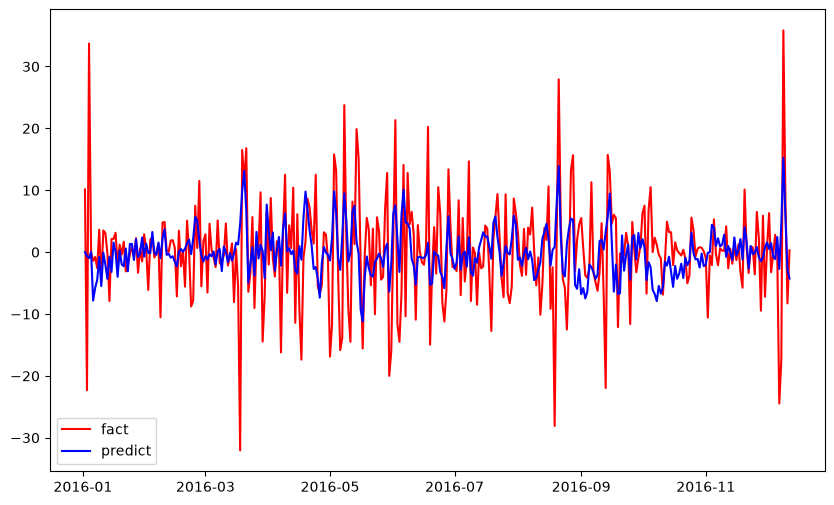

In [55]:
plt.figure(figsize=(10, 6))
plt.plot(humidity_seattle_2016_resample_diff,color='red')
plt.plot(forecast,color='blue')
plt.legend(['fact','predict'])
plt.show()

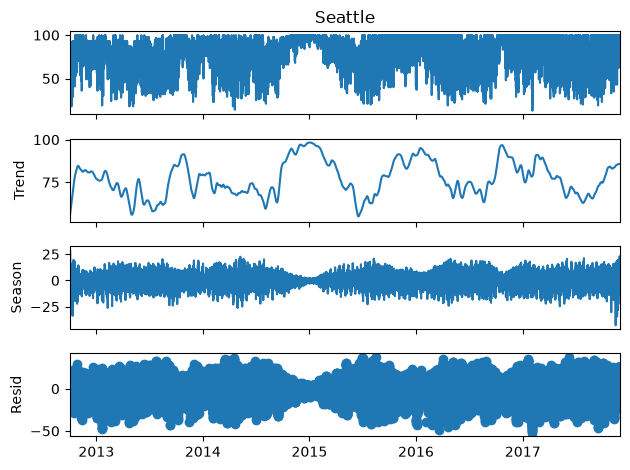

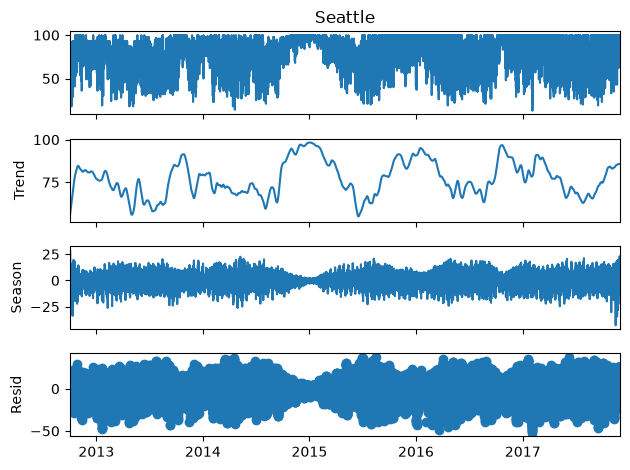

In [56]:
from statsmodels.tsa.seasonal import STL
stl = STL(humidity_seattle, period=365).fit()
stl.plot()

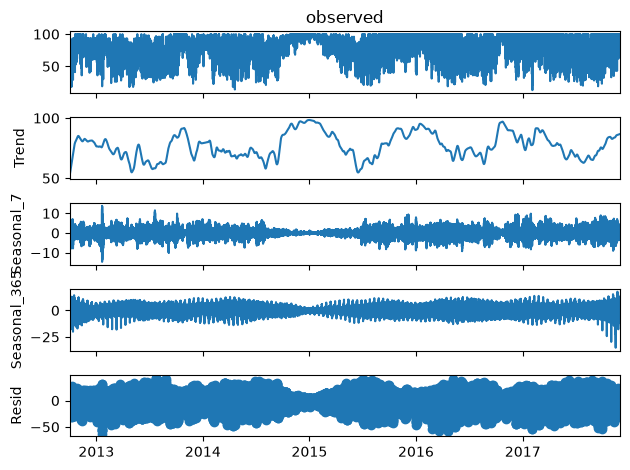

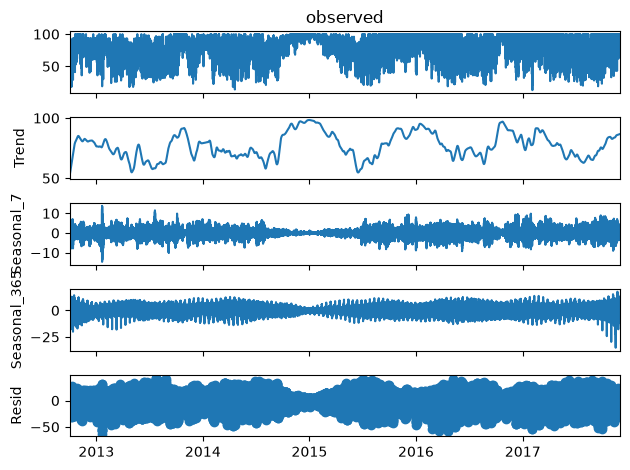

In [57]:
from statsmodels.tsa.seasonal import MSTL
mstl = MSTL(humidity_seattle, periods=[7, 365]).fit()
mstl.plot()

In [58]:
from statsmodels.tsa.seasonal import seasonal_decompose

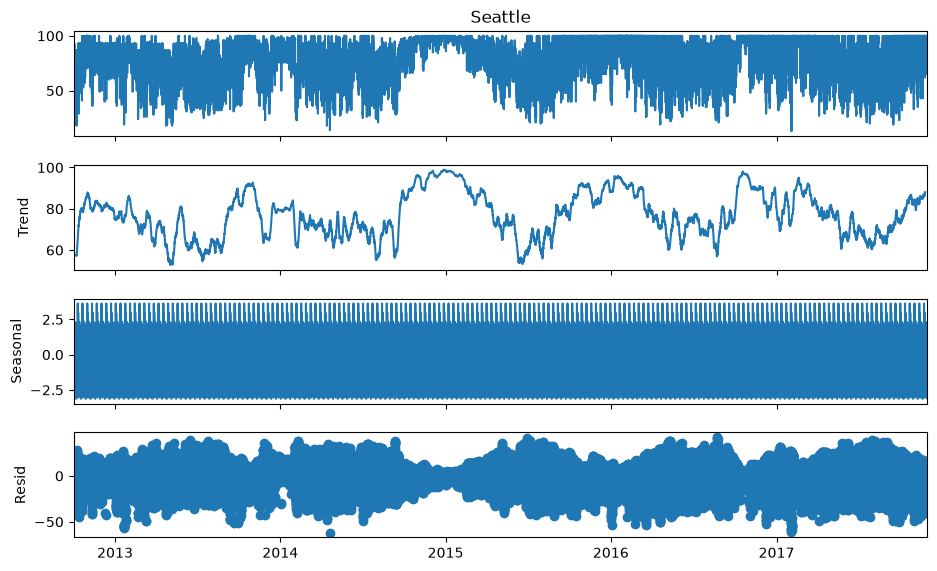

<Axes: xlabel='datetime'>

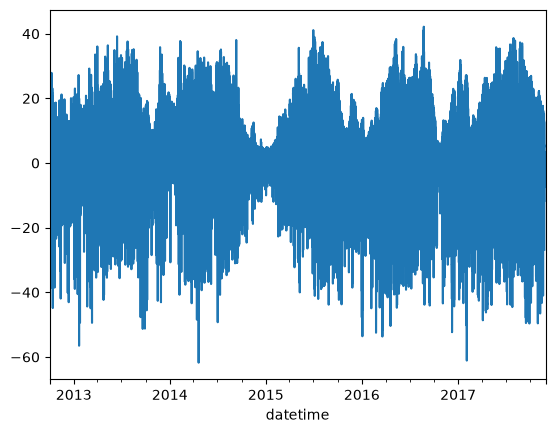

In [61]:
res = seasonal_decompose(humidity_seattle,  period=252)

fig = res.plot()
fig.set_size_inches(10, 6)
plt.show()

res.resid.plot()

In [73]:
humidity_seattle_2016.shape

(8328,)

In [74]:
8328 * 90 // 100

7495

In [75]:
train, test = humidity_seattle_2016[:7495], humidity_seattle_2016[7495:]

In [77]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.seasonal import STL

(366,)
2016-01-01 00:00:00 2016-12-31 00:00:00


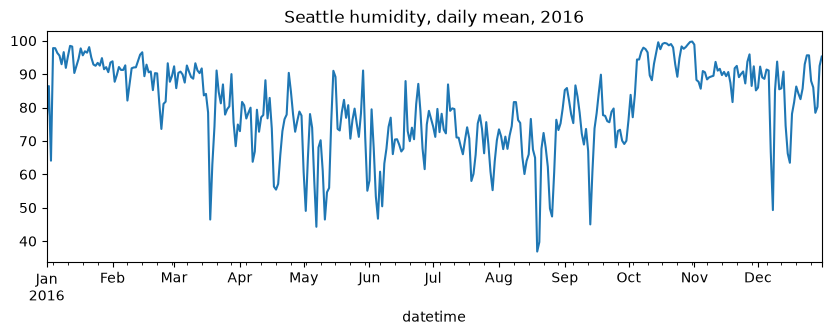

In [78]:
url = (
    "https://raw.githubusercontent.com/tirthajyoti/Deep-learning-with-Python/"
    "80f337d1584fb123f1a8f7dce0ad190f1a08ce14/"
    "Data/historical-hourly-weather-data/humidity.csv"
)
humidity = pd.read_csv(url, index_col='datetime', parse_dates=['datetime'])
humidity_seattle = humidity['Seattle'].ffill().iloc[1:]
humidity_seattle = humidity_seattle.sort_index()

y = humidity_seattle.loc['2016'].resample('D').mean()
print(y.shape)
print(y.index.min(), y.index.max())
y.plot(figsize=(10, 3), title='Seattle humidity, daily mean, 2016')
plt.show()

In [79]:
print('ADF p-value ', adfuller(y)[1])
print('KPSS p-value', kpss(y, regression='c', nlags='auto')[1])

ADF p-value  0.008292775356006615
KPSS p-value 0.02377630890479431


(365,)
ADF p-value  3.498029443130434e-21
KPSS p-value 0.1


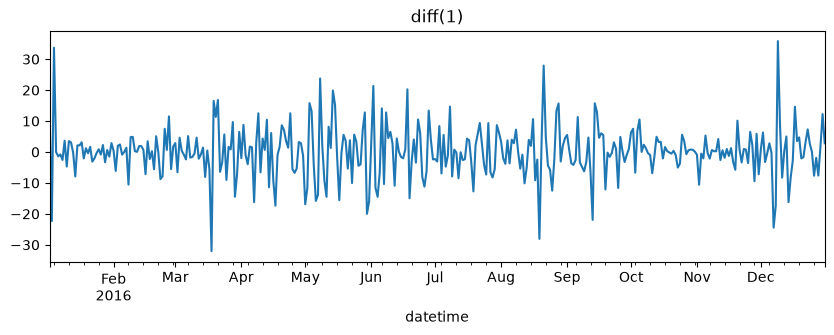

In [80]:
y_diff = y.diff().dropna()
print(y_diff.shape)
print('ADF p-value ', adfuller(y_diff)[1])
print('KPSS p-value', kpss(y_diff, regression='c', nlags='auto')[1])
y_diff.plot(figsize=(10, 3), title='diff(1)')
plt.show()

In [81]:
test_size = 30
train, test = y_diff.iloc[:-test_size], y_diff.iloc[-test_size:]
print('train', len(train), train.index.min().date(), train.index.max().date())
print('test ', len(test), test.index.min().date(), test.index.max().date())

train 335 2016-01-02 2016-12-01
test  30 2016-12-02 2016-12-31


      lb_stat  lb_pvalue
1    1.494081   0.221584
2   23.258234   0.000009
7   39.679113   0.000001
14  43.322453   0.000076


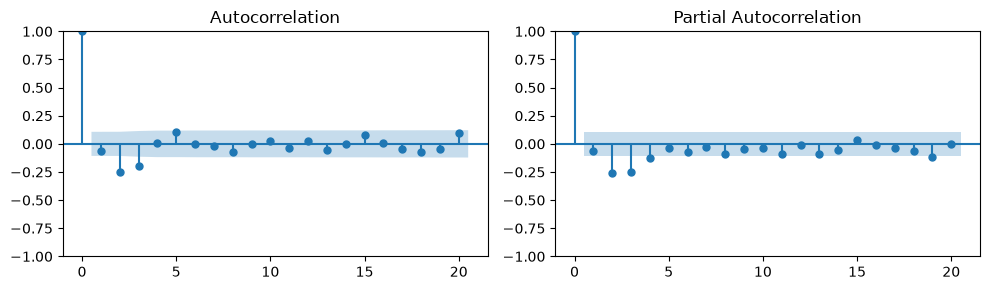

In [82]:
print(acorr_ljungbox(train, return_df=True, lags=[1, 2, 7, 14]))
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
plot_acf(train, ax=ax[0], lags=20)
plot_pacf(train, ax=ax[1], lags=20)
plt.tight_layout()
plt.show()

In [83]:
rows = []
for p in range(0, 4):
    for q in range(0, 4):
        res = ARIMA(train, order=(p, 0, q)).fit()
        rows.append({'p': p, 'q': q, 'AIC': res.aic, 'BIC': res.bic})
models = pd.DataFrame(rows).sort_values('AIC')
models

,p,q,AIC,BIC
3,0,3,2281.115289,2300.185942
9,2,1,2282.730418,2301.801071
7,1,3,2283.087637,2305.972421
6,1,2,2283.384822,2302.455474
15,3,3,2283.687764,2314.200808
13,3,1,2284.439978,2307.324762
10,2,2,2284.614379,2307.499162
11,2,3,2284.926827,2311.625741
14,3,2,2286.685986,2313.384900
5,1,1,2290.683523,2305.940045


In [84]:
res = ARIMA(train, order=(0, 0, 3)).fit()
print(res.summary())

                               SARIMAX Results                                
Dep. Variable:                Seattle   No. Observations:                  335
Model:                 ARIMA(0, 0, 3)   Log Likelihood               -1135.558
Date:                Tue, 06 Oct 2026   AIC                           2281.115
Time:                        15:02:35   BIC                           2300.186
Sample:                    01-02-2016   HQIC                          2288.718
                         - 12-01-2016                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0034      0.102      0.033      0.974      -0.196       0.203
ma.L1         -0.2260      0.042     -5.369      0.000      -0.308      -0.143
ma.L2         -0.3184      0.046     -6.913      0.0

     lb_stat  lb_pvalue
1   0.000067        NaN
2   0.012106        NaN
7   3.127094   0.536786
14  7.538445   0.753955


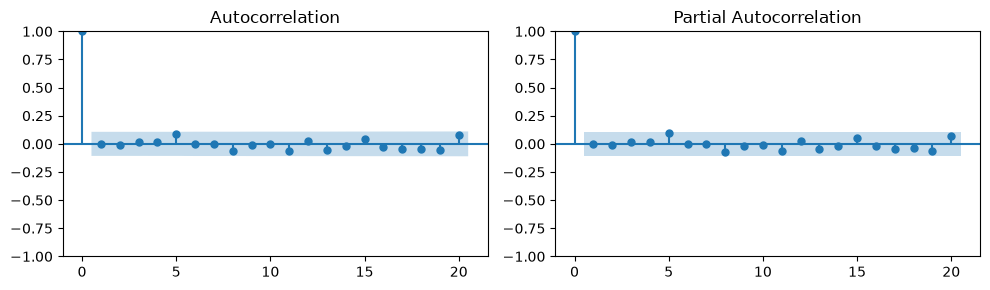

In [85]:
resid = res.resid.dropna()
print(acorr_ljungbox(resid, return_df=True, lags=[1, 2, 7, 14], model_df=3))
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
plot_acf(resid, ax=ax[0], lags=20)
plot_pacf(resid, ax=ax[1], lags=20)
plt.tight_layout()
plt.show()

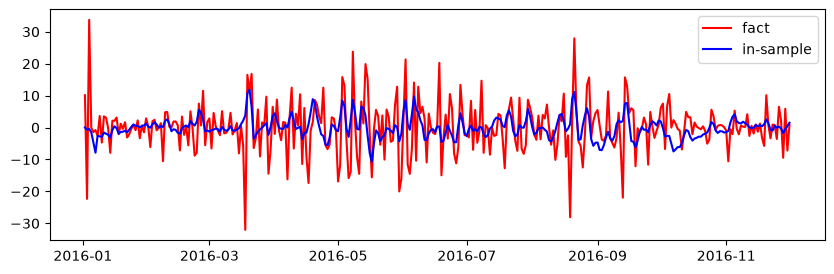

In [86]:
pred = res.predict()
plt.figure(figsize=(10, 3))
plt.plot(train, color='red', label='fact')
plt.plot(pred, color='blue', label='in-sample')
plt.legend()
plt.show()

MAE model 7.165257971522293
MAE naive 7.1319444444444455


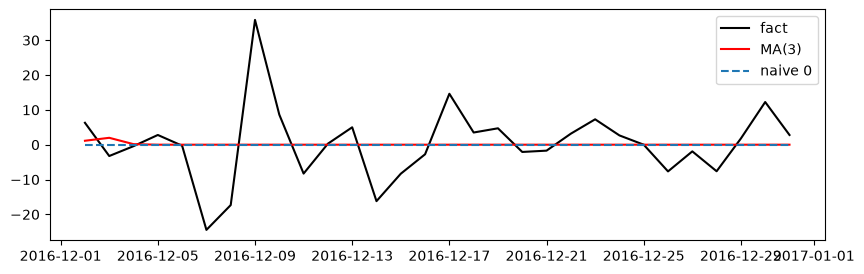

In [87]:
fc = res.forecast(steps=len(test))
naive = pd.Series(0, index=test.index)
print('MAE model', np.mean(np.abs(test - fc)))
print('MAE naive', np.mean(np.abs(test - naive)))

plt.figure(figsize=(10, 3))
plt.plot(test.index, test, color='black', label='fact')
plt.plot(test.index, fc, color='red', label='MA(3)')
plt.plot(test.index, naive, ls='--', label='naive 0')
plt.legend()
plt.show()

MAE model 8.000077803072546
MAE naive 7.395833333333333


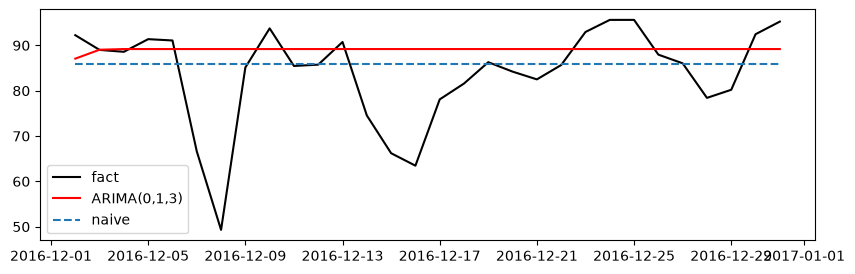

In [88]:
y_train, y_test = y.iloc[:-test_size], y.iloc[-test_size:]
res_level = ARIMA(y_train, order=(0, 1, 3)).fit()
fc_level = res_level.forecast(steps=len(y_test))
naive_level = pd.Series(y_train.iloc[-1], index=y_test.index)
print('MAE model', np.mean(np.abs(y_test - fc_level)))
print('MAE naive', np.mean(np.abs(y_test - naive_level)))

plt.figure(figsize=(10, 3))
plt.plot(y_test.index, y_test, color='black', label='fact')
plt.plot(y_test.index, fc_level, color='red', label='ARIMA(0,1,3)')
plt.plot(y_test.index, naive_level, ls='--', label='naive')
plt.legend()
plt.show()

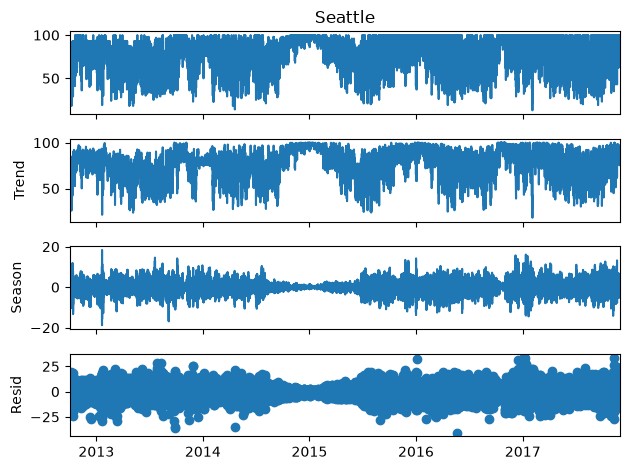

In [92]:
stl = STL(humidity_seattle, period=7).fit()
stl.plot()
plt.show()

In [96]:
# import sys
# !{sys.executable} -m pip install --trusted-host pypi.org --trusted-host files.pythonhosted.org pmdarima

In [95]:
import pmdarima as pm

In [97]:
model = pm.auto_arima(y_train, seasonal=False, max_p=3, max_q=3, trace=True)

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=2284.615, Time=0.23 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=2335.929, Time=0.01 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=2336.443, Time=0.03 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=2334.394, Time=0.05 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=2333.934, Time=0.01 sec
 ARIMA(1,1,2)(0,0,0)[0] intercept   : AIC=2283.385, Time=0.11 sec
 ARIMA(0,1,2)(0,0,0)[0] intercept   : AIC=2292.103, Time=0.08 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=2290.684, Time=0.11 sec
 ARIMA(1,1,3)(0,0,0)[0] intercept   : AIC=2283.089, Time=0.15 sec
 ARIMA(0,1,3)(0,0,0)[0] intercept   : AIC=2281.116, Time=0.11 sec
 ARIMA(0,1,3)(0,0,0)[0]             : AIC=2279.118, Time=0.08 sec
 ARIMA(0,1,2)(0,0,0)[0]             : AIC=2290.117, Time=0.04 sec
 ARIMA(1,1,3)(0,0,0)[0]             : AIC=2281.090, Time=0.10 sec
 ARIMA(1,1,2)(0,0,0)[0]             : AIC=2281.387, Time=0.07 sec

Best model:  ARIMA(0,1,3)(0,0,0)

In [98]:
X = pd.DataFrame(index=y.index)
X['winter'] = y.index.month.isin([1, 2, 12]).astype(int)
X['weekend'] = (y.index.dayofweek >= 5).astype(int)

y_train, y_test = y.iloc[:-30], y.iloc[-30:]
resx = ARIMA(y_train, order=(0, 1, 3), exog=X.loc[y_train.index]).fit()
print(resx.summary())

fcx = resx.forecast(steps=len(y_test), exog=X.loc[y_test.index])

                               SARIMAX Results                                
Dep. Variable:                Seattle   No. Observations:                  336
Model:                 ARIMA(0, 1, 3)   Log Likelihood               -1134.613
Date:                Tue, 06 Oct 2026   AIC                           2281.226
Time:                        16:38:43   BIC                           2304.111
Sample:                    01-01-2016   HQIC                          2290.350
                         - 12-01-2016                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
winter        -1.0429     11.447     -0.091      0.927     -23.479      21.393
weekend        1.1823      0.940      1.257      0.209      -0.661       3.025
ma.L1         -0.2246      0.041     -5.465      0.0

In [99]:
X

,winter,weekend
datetime,,
2016-01-01,1,0
2016-01-02,1,1
2016-01-03,1,1
2016-01-04,1,0
2016-01-05,1,0
...,...,...
2016-12-27,1,0
2016-12-28,1,0
2016-12-29,1,0


In [165]:
X = pd.read_csv("cafe_sales_2024.csv", index_col="date", parse_dates="date")

TypeError: Only booleans and lists are accepted for the 'parse_dates' parameter

In [159]:
X

,date,sales
0,2024-01-01,80.0
1,2024-01-02,85.9
2,2024-01-03,85.4
3,2024-01-04,78.9
4,2024-01-05,74.0
...,...,...
361,2024-12-27,100.2
362,2024-12-28,112.8
363,2024-12-29,110.8
364,2024-12-30,89.2


In [164]:
X = pd.read_csv(X, index_col="datetime", parse_dates="date")

TypeError: argument of type 'method' is not iterable

In [102]:
# с 18 по 31 декабря

(366,)


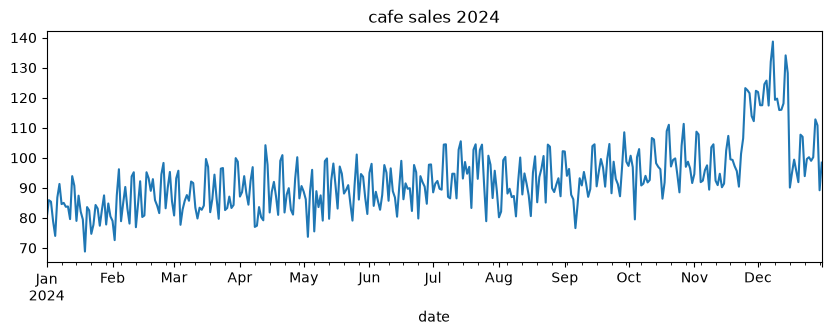

In [103]:
df = pd.read_csv('cafe_sales_2024.csv', parse_dates=['date'], index_col='date')
y = df['sales'].sort_index()
print(y.shape)
y.plot(figsize=(10, 3), title='cafe sales 2024')
plt.show()

In [104]:
test_size = 14
y_train, y_test = y.iloc[:-test_size], y.iloc[-test_size:]
print(y_train.index.max().date(), y_test.index.min().date(), y_test.index.max().date())
print('ADF ', adfuller(y_train)[1])
print('KPSS', kpss(y_train, regression='c', nlags='auto')[1])

2024-12-17 2024-12-18 2024-12-31
ADF  0.22898514407051612
KPSS 0.01


In [105]:
y_diff = y_train.diff().dropna()
print('ADF ', adfuller(y_diff)[1])
print('KPSS', kpss(y_diff, regression='c', nlags='auto')[1])

ADF  0.00013083889683042905
KPSS 0.1


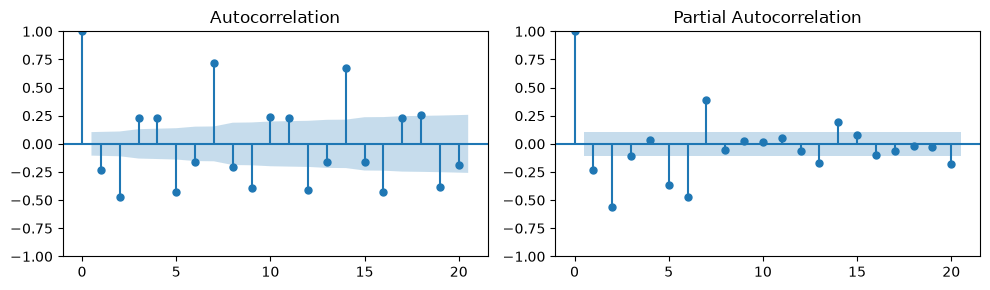

       lb_stat      lb_pvalue
1    18.915736   1.366211e-05
7   399.064278   3.786143e-82
14  746.002842  3.868076e-150


In [106]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
plot_acf(y_diff, ax=ax[0], lags=20)
plot_pacf(y_diff, ax=ax[1], lags=20)
plt.tight_layout()
plt.show()
print(acorr_ljungbox(y_diff, return_df=True, lags=[1, 7, 14]))

In [107]:
X = pd.DataFrame(index=y.index)
X['weekend'] = y.index.dayofweek.isin([5, 6]).astype(int)
X['promo'] = (
    ((y.index.month == 11) & (y.index.day >= 25))
    | ((y.index.month == 12) & (y.index.day <= 15))
).astype(int)
X.loc[y_test.index]

,weekend,promo
date,,
2024-12-18,0,0
2024-12-19,0,0
2024-12-20,0,0
2024-12-21,1,0
2024-12-22,1,0
2024-12-23,0,0
2024-12-24,0,0
2024-12-25,0,0
2024-12-26,0,0


In [108]:
rows = []
for p in range(0, 4):
    for q in range(0, 4):
        res = ARIMA(y_train, order=(p, 1, q)).fit()
        rows.append({'p': p, 'q': q, 'AIC': res.aic})
models = pd.DataFrame(rows).sort_values('AIC')
models.head()

,p,q,AIC
15,3,3,2236.126375
11,2,3,2263.768012
13,3,1,2361.465205
14,3,2,2362.905193
10,2,2,2365.494413


In [113]:
res = ARIMA(y_train, order=(3, 0, 3)).fit()
print(res.summary())
resid = res.resid.dropna()
print(acorr_ljungbox(resid, return_df=True, lags=[1, 7, 14], model_df=2))

                               SARIMAX Results                                
Dep. Variable:                  sales   No. Observations:                  352
Model:                 ARIMA(3, 0, 3)   Log Likelihood               -1128.963
Date:                Tue, 06 Oct 2026   AIC                           2273.926
Time:                        16:50:04   BIC                           2304.835
Sample:                    01-01-2024   HQIC                          2286.226
                         - 12-17-2024                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         92.7481     10.728      8.645      0.000      71.721     113.775
ar.L1          0.5457      0.011     48.309      0.000       0.524       0.568
ar.L2         -0.5547      0.006    -98.354      0.0

In [114]:
fc = res.forecast(steps=len(y_test))
naive = pd.Series(y_train.iloc[-1], index=y_test.index)
print('MAE ARIMA', np.mean(np.abs(y_test - fc)))
print('MAE naive', np.mean(np.abs(y_test - naive)))

MAE ARIMA 8.053333640993
MAE naive 6.8428571428571425


In [115]:
resx = ARIMA(
    y_train,
    order=(3, 0, 3),
    exog=X.loc[y_train.index],
).fit()
print(resx.summary())
fcx = resx.forecast(steps=len(y_test), exog=X.loc[y_test.index])
print('MAE ARIMAX', np.mean(np.abs(y_test - fcx)))

                               SARIMAX Results                                
Dep. Variable:                  sales   No. Observations:                  352
Model:                 ARIMA(3, 0, 3)   Log Likelihood               -1020.535
Date:                Tue, 06 Oct 2026   AIC                           2061.071
Time:                        16:50:13   BIC                           2099.707
Sample:                    01-01-2024   HQIC                          2076.446
                         - 12-17-2024                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         87.2282      6.046     14.427      0.000      75.378      99.079
weekend       12.6659      0.740     17.110      0.000      11.215      14.117
promo         25.5105      2.610      9.774      0.0

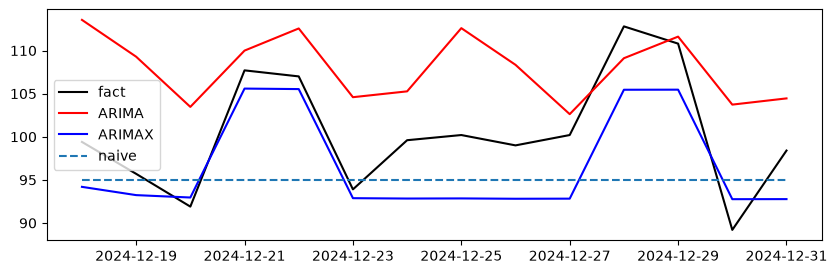

In [116]:
plt.figure(figsize=(10, 3))
plt.plot(y_test.index, y_test, color='black', label='fact')
plt.plot(y_test.index, fc, color='red', label='ARIMA')
plt.plot(y_test.index, fcx, color='blue', label='ARIMAX')
plt.plot(y_test.index, naive, ls='--', label='naive')
plt.legend()
plt.show()

In [125]:
df = pd.read_csv('museum_visitors.csv', parse_dates=['date'], index_col='date')
df.head(1)

,visitors
date,
2023-01-01,125.3


Нужно спрогнозировать последние 21 день и сравнить с фактом. Эти дни отложи до тестов и выбора порядка.

Гипотеза кассира: выходные и короткие праздники отличаются от обычных дней. Праздники возьми 1–7 января, 1, 2 и 9 мая, 29–31 декабря. Колонки в файле нет, их можно проставить по календарю и на test тоже.

В ответе нужны d, порядок модели, остатки и три ошибки на 21 дне: модель, модель с этими колонками, наивный «как в последний день train». Решение не прилагаю.

In [127]:
y = df['visitors'].sort_index()
y

date
2023-01-01    125.3
2023-01-02    159.6
2023-01-03    136.9
2023-01-04    166.1
2023-01-05    145.9
              ...  
2024-06-26    128.5
2024-06-27    141.1
2024-06-28    138.0
2024-06-29    109.2
2024-06-30    111.7
Name: visitors, Length: 547, dtype: float64

In [129]:
test = 21
y_train, y_test = y.iloc[:-test_size], y.iloc[-test_size:]

In [130]:
adfuller(y_train)[1]

0.527927579256244

In [132]:
kpss(y_train)[1]

np.float64(0.01)

In [135]:
y_diff = y_train.diff().dropna()

In [137]:
adfuller(y_diff)[1]

5.179921469976271e-12

In [140]:
kpss(y_diff)[1]

np.float64(0.1)

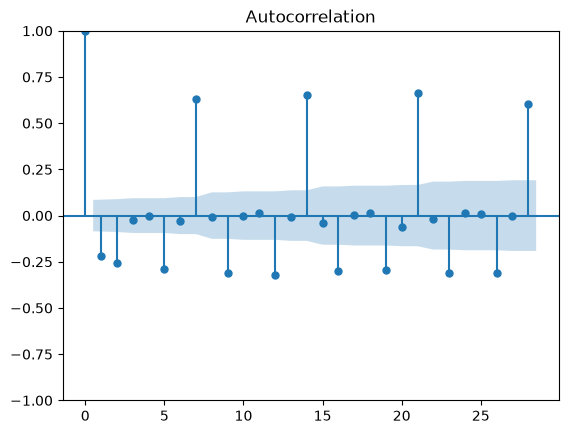

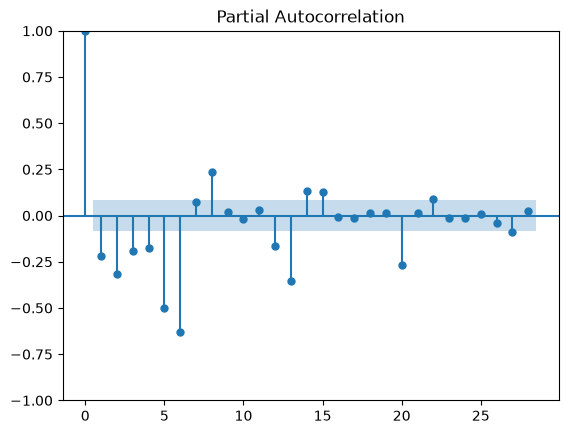

In [144]:
plot_acf(y_diff)
plot_pacf(y_diff)
plt.show()

In [145]:
model = pm.auto_arima(y_train, seasonal=False, max_p=3, max_q=3, trace=True)

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=4240.338, Time=0.43 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=4517.556, Time=0.01 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=4493.651, Time=0.09 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=4346.621, Time=0.08 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=4515.557, Time=0.01 sec
 ARIMA(1,1,2)(0,0,0)[0] intercept   : AIC=4296.506, Time=0.18 sec
 ARIMA(2,1,1)(0,0,0)[0] intercept   : AIC=4282.441, Time=0.15 sec
 ARIMA(3,1,2)(0,0,0)[0] intercept   : AIC=4228.876, Time=0.60 sec
 ARIMA(3,1,1)(0,0,0)[0] intercept   : AIC=4277.341, Time=0.28 sec
 ARIMA(3,1,3)(0,0,0)[0] intercept   : AIC=inf, Time=1.02 sec
 ARIMA(2,1,3)(0,0,0)[0] intercept   : AIC=inf, Time=0.88 sec
 ARIMA(3,1,2)(0,0,0)[0]             : AIC=4226.936, Time=0.32 sec
 ARIMA(2,1,2)(0,0,0)[0]             : AIC=4238.393, Time=0.16 sec
 ARIMA(3,1,1)(0,0,0)[0]             : AIC=4275.356, Time=0.16 sec
 ARIMA(3,1,3)(0,0,0)[0]             : AIC=i

In [149]:
res = ARIMA(y_train, order=(3, 1, 2)).fit()
print(res.summary())

                               SARIMAX Results                                
Dep. Variable:               visitors   No. Observations:                  533
Model:                 ARIMA(3, 1, 2)   Log Likelihood               -2107.468
Date:                Tue, 06 Oct 2026   AIC                           4226.936
Time:                        17:05:25   BIC                           4252.596
Sample:                    01-01-2023   HQIC                          4236.978
                         - 06-16-2024                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.7850      0.065     12.057      0.000       0.657       0.913
ar.L2         -0.4313      0.057     -7.615      0.000      -0.542      -0.320
ar.L3         -0.2172      0.055     -3.970      0.0

       lb_stat     lb_pvalue
1     0.030979           NaN
2    10.694885           NaN
7   140.567452  2.133811e-29
14  377.852319  3.056904e-74


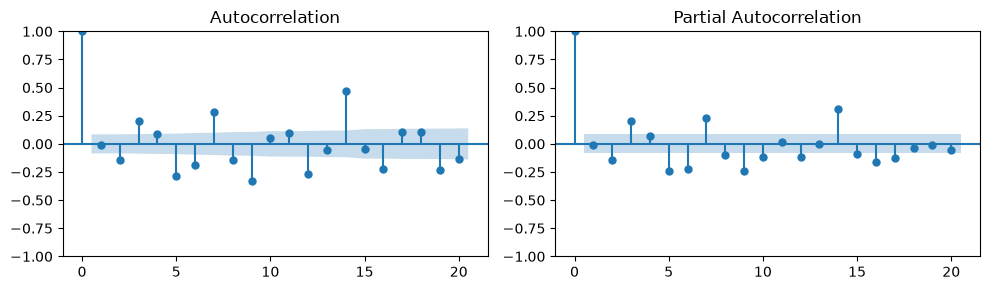

In [150]:
resid = res.resid.dropna()
print(acorr_ljungbox(resid, return_df=True, lags=[1, 2, 7, 14], model_df=3))
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
plot_acf(resid, ax=ax[0], lags=20)
plot_pacf(resid, ax=ax[1], lags=20)
plt.tight_layout()
plt.show()

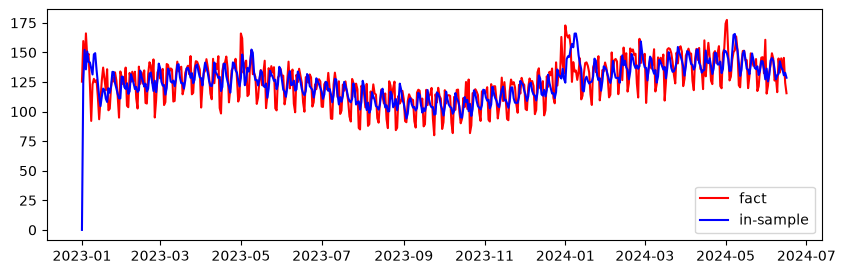

In [151]:
pred = res.predict()
plt.figure(figsize=(10, 3))
plt.plot(y_train, color='red', label='fact')
plt.plot(pred, color='blue', label='in-sample')
plt.legend()
plt.show()

MAE model 9.715866665883087
MAE naive 131.09285714285713


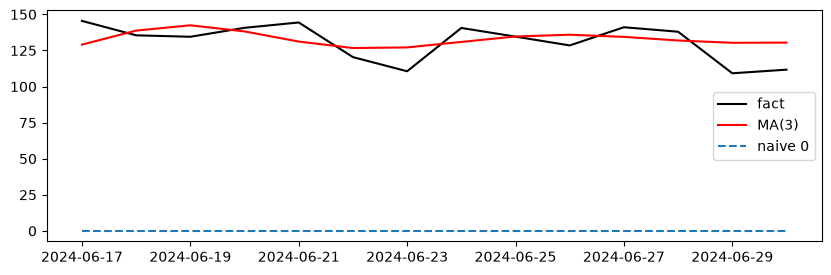

In [155]:
fc = res.forecast(steps=len(y_test))
naive = pd.Series(0, index=y_test.index)
print('MAE model', np.mean(np.abs(y_test - fc)))
print('MAE naive', np.mean(np.abs(y_test - naive)))

plt.figure(figsize=(10, 3))
plt.plot(y_test.index, y_test, color='black', label='fact')
plt.plot(y_test.index, fc, color='red', label='MA(3)')
plt.plot(y_test.index, naive, ls='--', label='naive 0')
plt.legend()
plt.show()

In [156]:
X = pd.DataFrame(index=y.index)
X['weekend'] = y.index.dayofweek.isin([5, 6]).astype(int)
X['holiday'] = (
    ((y.index.month == 1) & (y.index.day <= 7))
    | ((y.index.month == 5) & (y.index.day.isin([1, 2, 9])))
    | ((y.index.month == 12) & (y.index.day >= 29))
).astype(int)
print(X.loc[y_test.index].sum())

weekend    4
holiday    0
dtype: int64


In [157]:
X


,weekend,holiday
date,,
2023-01-01,1,1
2023-01-02,0,1
2023-01-03,0,1
2023-01-04,0,1
2023-01-05,0,1
...,...,...
2024-06-26,0,0
2024-06-27,0,0
2024-06-28,0,0


In [172]:
df = pd.read_csv('shop_sales.csv', parse_dates=['date'], index_col='date')
df

,sales
date,
2024-03-01,40.0
2024-03-02,44.4
2024-03-03,51.0
2024-03-04,38.0
2024-03-05,38.1
...,...
2024-08-27,49.8
2024-08-28,48.5
2024-08-29,51.6


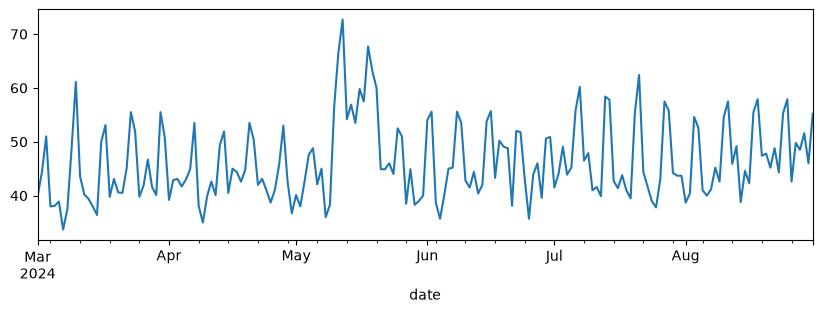

date
2024-03-01    40.0
2024-03-02    44.4
2024-03-03    51.0
2024-03-04    38.0
2024-03-05    38.1
              ... 
2024-08-27    49.8
2024-08-28    48.5
2024-08-29    51.6
2024-08-30    46.0
2024-08-31    55.2
Name: sales, Length: 184, dtype: float64

In [175]:
df = pd.read_csv('shop_sales.csv', parse_dates=['date'], index_col='date')
y = df['sales'].sort_index()
y.plot(figsize=(10, 3))
plt.show()
y

In [169]:
df.head()

,sales
date,
2024-03-01,40.0
2024-03-02,44.4
2024-03-03,51.0
2024-03-04,38.0
2024-03-05,38.1


In [168]:
test_size = 14
y_train, y_test = y.iloc[:-test_size], y.iloc[-test_size:]
print(adfuller(y_train)[1])
print(kpss(y_train, regression='c', nlags='auto')[1])

0.007622429901930099
0.1


In [174]:
X = pd.DataFrame(index=y.index)
# y = df['sales'].sort_index()

In [177]:
X['weekend'] = y.index.dayofweek.isin([5, 6]).astype(int)
X['promo'] = (
    (y.index >= '2024-05-10') & (y.index <= '2024-05-20')
).astype(int)
print(X.loc[y_test.index].sum())

weekend    4
promo      0
dtype: int64


In [178]:
X

,weekend,promo
date,,
2024-03-01,0,0
2024-03-02,1,0
2024-03-03,1,0
2024-03-04,0,0
2024-03-05,0,0
...,...,...
2024-08-27,0,0
2024-08-28,0,0
2024-08-29,0,0


Магазин хочет знать выручку с 18 по 31 августа. Эти 14 дней модель видеть не должна. \
Гипотеза управляющего: по субботам и воскресеньям покупают больше, а с 10 по 20 мая была акция и выручка тоже была другой. Оба факта известны из календаря, в файле их нет. Нужно проверить, становится ли прогноз на август точнее, если добавить эти две колонки. \
Сравни три ошибки на одних и тех же 14 днях: модель без колонок, модель с ними и «завтра как в последний день train». Если колонки не уменьшают ошибку и коэффициенты незначимы, в прогноз их не кладут. Акция в августе уже не идёт, так что на этом хвосте работать может только признак выходного.

In [181]:
res = ARIMA(y_train, order=(1, 0, 0)).fit()
resx = ARIMA(y_train, order=(1, 0, 0), exog=X.loc[y_train.index]).fit()
print(resx.summary())

                               SARIMAX Results                                
Dep. Variable:                  sales   No. Observations:                  170
Model:                 ARIMA(1, 0, 0)   Log Likelihood                -439.039
Date:                Wed, 07 Oct 2026   AIC                            888.079
Time:                        16:27:17   BIC                            903.758
Sample:                    03-01-2024   HQIC                           894.441
                         - 08-17-2024                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         41.7632      0.464     90.002      0.000      40.854      42.673
weekend       11.4935      0.565     20.332      0.000      10.386      12.602
promo         15.0451      1.436     10.480      0.0

In [182]:
fc = res.forecast(steps=len(y_test))
fcx = resx.forecast(steps=len(y_test), exog=X.loc[y_test.index])
naive = pd.Series(y_train.iloc[-1], index=y_test.index)

print('MAE без dummy', np.mean(np.abs(y_test - fc)))
print('MAE с dummy ', np.mean(np.abs(y_test - fcx)))
print('MAE naive   ', np.mean(np.abs(y_test - naive)))

MAE без dummy 4.289504150245719
MAE с dummy  4.754947638521754
MAE naive    6.307142857142857


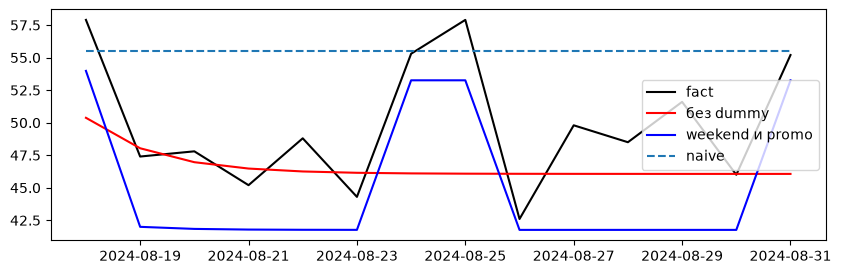

In [183]:
plt.figure(figsize=(10, 3))
plt.plot(y_test.index, y_test, color='black', label='fact')
plt.plot(y_test.index, fc, color='red', label='без dummy')
plt.plot(y_test.index, fcx, color='blue', label='weekend и promo')
plt.plot(y_test.index, naive, ls='--', label='naive')
plt.legend()
plt.show()

In [188]:
df = pd.read_csv('metrics_series.csv', parse_dates=['date'], index_col='date')
s = df['sales'].sort_index()
print(s.head())

date
2024-05-01    101.0
2024-05-02    108.7
2024-05-03    108.8
2024-05-04     99.6
2024-05-05     99.2
Name: sales, dtype: float64


In [189]:
train, test = s.iloc[:-14], s.iloc[-14:]
print(len(train), len(test))

35 14


In [190]:
last = train.iloc[-7:].to_numpy()
naive = pd.Series(np.resize(last, len(test)), index=test.index)

In [191]:
model = test.shift(1)
model.iloc[0] = train.iloc[-1]
model = (0.7 * model + 0.3 * test.mean()).round(1)
model.iloc[5] = 90
model.iloc[10] = 110

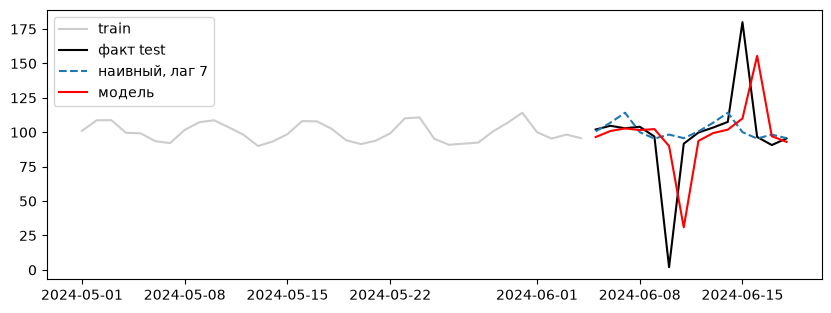

In [192]:
plt.figure(figsize=(10, 3.5))
plt.plot(train.index, train, color='0.8', label='train')
plt.plot(test.index, test, color='black', label='факт test')
plt.plot(test.index, naive, ls='--', label='наивный, лаг 7')
plt.plot(test.index, model, color='red', label='модель')
plt.legend()
plt.show()

In [193]:
def metrics(y, yhat, train, m=7):
    err = y - yhat
    nz = y != 0
    den = y.abs() + yhat.abs()
    return {
        'MAE': np.mean(np.abs(err)),
        'RMSE': np.sqrt(np.mean(err ** 2)),
        'MAPE': np.mean(np.abs(err[nz] / y[nz])) * 100,
        'WAPE': np.abs(err).sum() / np.abs(y).sum() * 100,
        'MDAPE': np.median(np.abs(err[nz] / y[nz])) * 100,
        'MASE': np.mean(np.abs(err)) / train.diff(m).abs().mean(),
        'SMAPE': (2 * err.abs() / den.replace(0, 1)).mean() * 100,
    }

tab = pd.DataFrame({
    'naive': metrics(test, naive, train),
    'model': metrics(test, model, train),
}).T
tab

,MAE,RMSE,MAPE,WAPE,MDAPE,MASE,SMAPE
naive,15.750000,33.745550,350.268161,16.004936,3.567456,6.456808,20.876410
model,22.821429,37.816521,329.144884,23.190825,5.482456,9.355783,30.546445


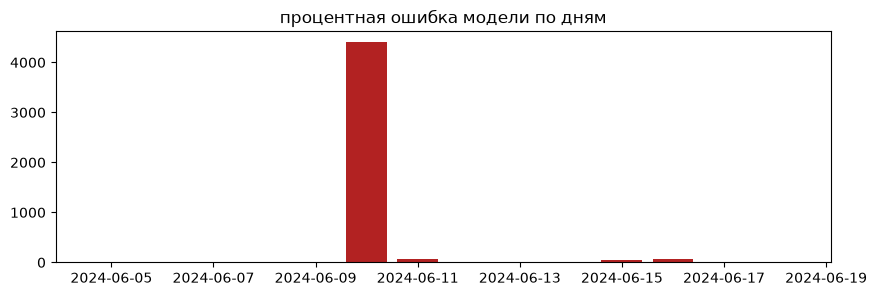

In [194]:
pe = (np.abs(test - model) / test) * 100
plt.figure(figsize=(10, 3))
plt.bar(test.index, pe, color='firebrick')
plt.title('процентная ошибка модели по дням')
plt.show()

In [331]:
df = pd.read_csv("cafe_sales_2024.csv", index_col="date", parse_dates=["date"])

In [332]:
df.head(1)

,sales
date,
2024-01-01,80.0


In [333]:
df.tail(1)

,sales
date,
2024-12-31,98.4


<Axes: xlabel='date'>

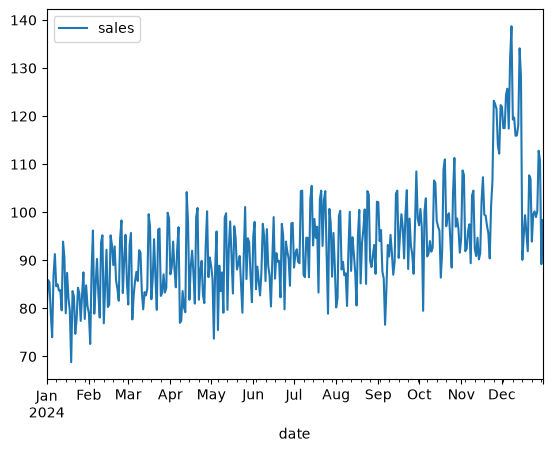

In [334]:
df.plot()

In [335]:
df.shape

(366, 1)

In [336]:
366 // 100 * 80

240

In [337]:
df.isnull().sum()

sales    0
dtype: int64

In [338]:
df

,sales
date,
2024-01-01,80.0
2024-01-02,85.9
2024-01-03,85.4
2024-01-04,78.9
2024-01-05,74.0
...,...
2024-12-27,100.2
2024-12-28,112.8
2024-12-29,110.8


In [ ]:
df = pd.read_csv("cafe_sales_2024.csv", index_col="date", parse_dates=["date"])